# Historico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de datos

Las [Historico de Bitácoras Onomásticas del Servicio Médico Forense del Distrito Federal (SEMEFO-DF)](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai), han sido sistematizada por la Comisión Nacional de Búsqueda (CNB). Este conjunto de datos se obtuvo a través de una solicitud de acceso a la información disponible en el Portal de Transparencia del Instituto Nacional de acceso a la Información (INAI) en noviembre de 2023 y existe una copia en el portal ciudadano _datamx_ de Codeando México.

El **SEMEFO-DF (Servicio Médico Forense Distrito Federal)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. Las **Bitácoras Onomásticas (BO)** son registros administrativos históricos utilizados por el SEMEFO para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. Estas bitácoras contienen información detallada sobre cada ingreso, como el nombre de la persona fallecida, su edad, sexo, fecha de ingreso, institución de procedencia y diagnóstico preliminar de causa de muerte. En muchos casos, estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Podemos acceder a esta información con la [Plataforma de Transparencia](https://www.plataformadetransparencia.org.mx/Inicio) o en [datamx](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai).

In [1]:
from numpy import nan
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from joblib import load

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)
        
df.tail()

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_diasemana,...,Diagnostico_clasificacion,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,Sábado,...,NaN,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,Sábado,...,NaN,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,Viernes,...,NaN,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,Domingo,...,NaN,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,Lunes,...,NaN,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


## Datos faltantes

### Datos faltantes por columna transcrita

In [2]:
col_trans = [c for c in df.columns if 'transcrito' in c]
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan = (df[col_trans]!='S-D')
df_notnan.sum()

Numero_progresivo_transcrito    27171
Nombre_completo_transcrito      96820
Fecha_transcrito                96611
Edad_transcrito                 40183
Diagnostico_transcrito          40966
Procedencia_transcrito          71064
Numero_acta_transcrito          71102
Expediente_SEMEFO_transcrito    96277
Foja_transcrito                 88864
dtype: int64

**Datos faltantes por año**

No todos los años se capturaron todas las variables.

* Edad y Diagnóstico solo fueron capturadas de 1974-1979
* Numero progresivo solo fue capturada de 1974 a 1978 y fue de manera irregular
* Procedencia y acta fueron capturadas de manera irregular de 1968 a 1963
* Foja no fue capturada en 1980

<AxesSubplot:ylabel='Bitacora'>

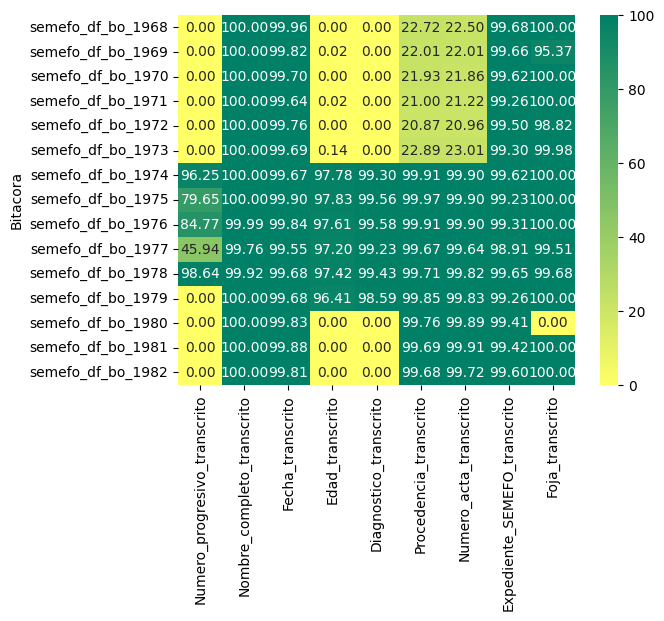

In [3]:
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan['Bitacora'] = df['Bitacora_ingresos']
df_notnan_anual = df_notnan.groupby('Bitacora').sum().divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap='summer_r', annot=True, fmt=".2f")

Ignorando las variables que no fueron capturadas en el año

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:10: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  # Remove the CWD from sys.path while we load stuff.


<AxesSubplot:ylabel='Bitacora'>

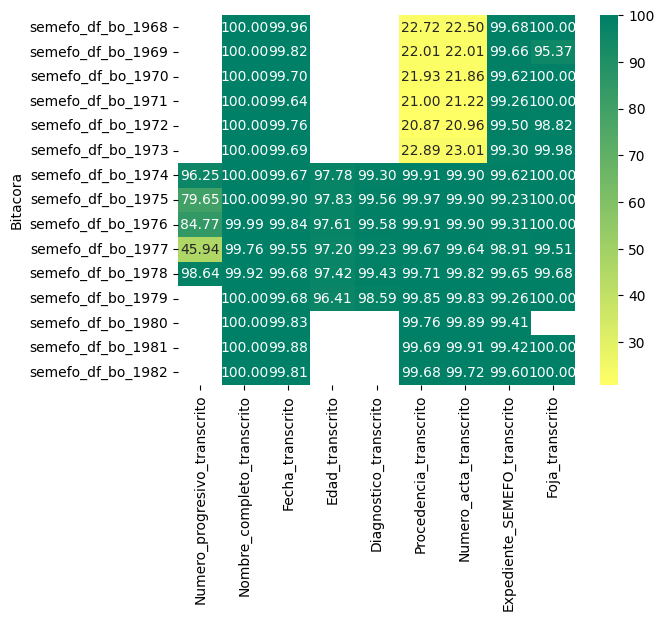

In [4]:
dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    df_notnan.loc[ df_notnan['Bitacora'].isin([f"semefo_df_bo_{a}" for a in años]), col] = nan
df_notnan

df_notnan_anual = df_notnan.groupby('Bitacora', dropna=False) \
                            .apply(lambda x: x.sum(skipna=False)) \
                            .divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap='summer_r', annot=True, fmt=".2f")

Correlación entre faltantes
* Existe una correlación alta  (0.996) entre la falta de procedencia y de acta.
* Existe una correlación debil entre la falta del nombre con la fecha (0.253) y el exp semefo (0.162)


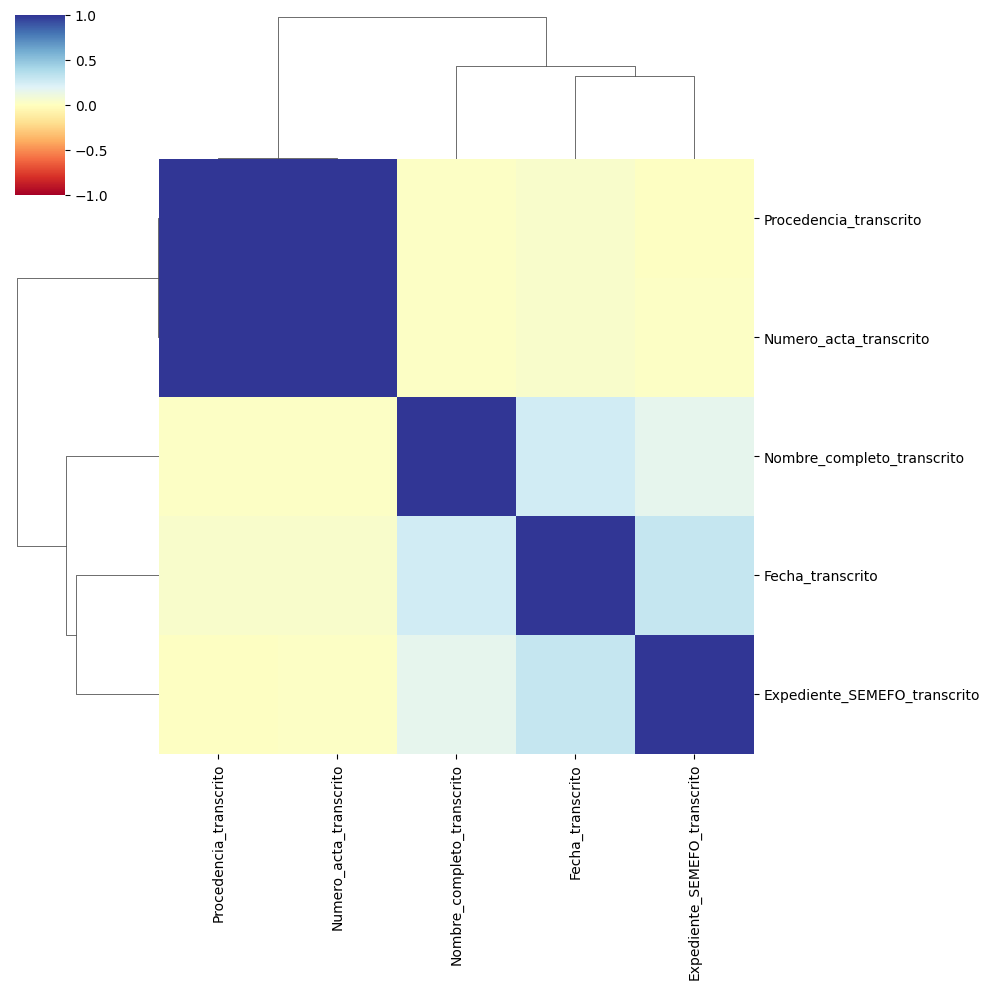

In [5]:
sns.clustermap(df_notnan.corr(), vmin=-1, vmax=1, cmap='RdYlBu')

**Faltantes de procedencia/acta de 1968-1973**

Mayoritariamente cadaver (99.33%) conocido (99.12%)

In [6]:
df_no_proc = df[(df['Procedencia_transcrito']=='S-D') | (df['Numero_acta_transcrito']=='S-D')]

for col in df_no_proc.columns:
    if df_no_proc[col].dtype=='category':
        print(col)
        display(df_no_proc[col].value_counts(normalize=True).head())


Fecha_año


1973.0    0.184873
1972.0    0.177492
1971.0    0.169451
1970.0    0.160671
1969.0    0.153446
Name: Fecha_año, dtype: float64

Fecha_mes


12.0    0.095991
1.0     0.087406
3.0     0.084920
5.0     0.084415
7.0     0.083482
Name: Fecha_mes, dtype: float64

Fecha_diasemana


...

HX       0.136752
GAM-2    0.094017
HB       0.085470
IZP-1    0.076923
HV       0.059829
Name: Procedencia_estandar, dtype: float64

Procedencia_alcaldia


Benito Juarez          0.189655
Gustavo A Madero       0.155172
Venustiano Carranza    0.137931
Cuauhtemoc             0.094828
Miguel Hidalgo         0.086207
Name: Procedencia_alcaldia, dtype: float64

Bitacora_ingresos


semefo_df_bo_1973    0.193545
semefo_df_bo_1972    0.176904
semefo_df_bo_1971    0.169105
semefo_df_bo_1970    0.160419
semefo_df_bo_1969    0.152697
Name: Bitacora_ingresos, dtype: float64

### Filas con más datos faltantes

* Casos donde hay número progresivo o foja pero ningun dato
* Casos donde solo hay nombre, muchas veces solo apellido
* Casos sin fecha pero con expediente

En general no parece haber un patrón, la cantidad de datos esta fuertemente asociada a que campos se capturaron ese año

In [7]:
df_notnan = (df[col_trans]!='S-D')
df_notnan['Bitacora'] = df['Bitacora_ingresos']

dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    años = [f"semefo_df_bo_{a}" for a in años]
    df_notnan.loc[ df_notnan['Bitacora'].isin(años), col] = nan

df_notnan_row = df_notnan.drop('Bitacora', axis=1).sum(axis=1).to_frame()
df_notnan_row.value_counts().sort_index()

1.0        6
2.0       76
3.0      460
4.0    25153
5.0     7900
6.0    22190
7.0      615
8.0    14044
9.0    26400
dtype: int64

<AxesSubplot:xlabel='0', ylabel='Bitacora'>

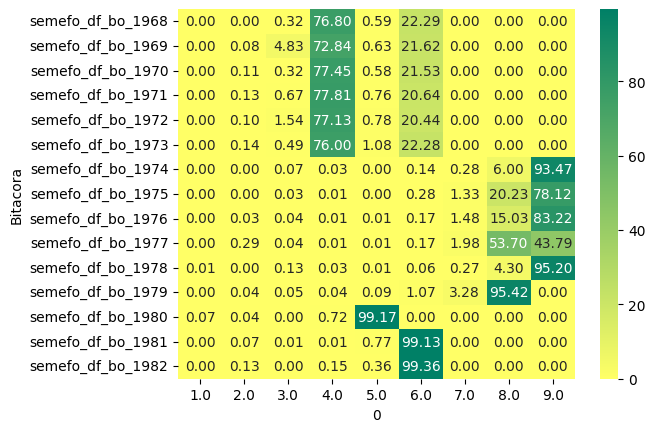

In [8]:
df_notnan_row['Bitacora'] = df['Bitacora_ingresos']
df_notnan_row_anual = df_notnan_row.pivot_table(columns=0, index='Bitacora', aggfunc='size')
df_notnan_row_anual = df_notnan_row_anual.divide(ingresos_anuales, axis=0)
sns.heatmap(df_notnan_row_anual*100, cmap='summer_r', annot=True, fmt=".2f")

## Resumen estadístico

### Tipo_restos
### Conocido_desconocido

In [22]:
df_desco = df.pivot_table(columns='Tipo_restos', index='Conocido_desconocido', aggfunc='size')
df_desco['Total'] = df_desco.sum(axis=1)
df_desco

Tipo_restos,Cadáver,Feto,Recién nacido,Miembros u óseos,Total
Conocido_desconocido,,,,,
Conocido,76756,31,31,1795,78613
Desconocido,14479,2813,602,318,18212
S-D,19,0,0,0,19


In [50]:
def categorical_to_freq_and_percentage(
    s: pd.Series,
    sort_index: bool = True,
    as_str: bool = True,
    top_n: int = None,
    percen_round: int = 3,
    dropna: bool = True
):
    """
    Summarizes a categorical Series with frequency and percentage per unique value.

    Parameters:
    - s (pd.Series): Input categorical data.
    - sort_index (bool): If True, sort output by index; if False, preserve order or sort by frequency.
    - as_str (bool): If True, return formatted strings like "count (percentage%)".
    - top_n (int): If provided, limit to top N categories by frequency.
    - percen_round (int): Decimal places for percentage rounding.
    - dropna (bool): Whether to exclude NaN values in the input series (default: True).

    Returns:
    - pd.Series or pd.DataFrame: Summary of categories.
    """
    # Calculate frequency and percentage
    freq = s.value_counts().astype(int)
    perc = (freq / len(s) * 100)
    # Round frequency
    if percen_round is not None:
        perc = perc.round(percen_round)
    # Create dataframe
    data = pd.concat([freq, perc], axis=1)
    data.columns = ['Frequency', 'Percentage']
    # Get top_n results
    if top_n is not None:
        data = data.sort_values('Frequency', ascending=False).head(top_n)
    # Sort index, uses categorical index if it exists
    if sort_index:
        data = data.sort_index()
    # Format to string
    if as_str:
        data = data.apply(lambda row: f"{int(row['Frequency'])} ({row['Percentage']}%)", axis=1)
    return data

categorical_to_freq_and_percentage(df['Tipo_restos'])

Cadáver             91254 (94.228%)
Feto                  2844 (2.937%)
Recién nacido          633 (0.654%)
Miembros u óseos      2113 (2.182%)
dtype: object

## Sexo y Edad

## Fecha

## Nombre

## Diagnostico

## Procedencia

## Expediente_SEMEFO
## Numero_acta

## Bitacora_ingresos
## Foja
## Observaciones